# Unrotated Bell-prep surgery across a straight seam

`surgery_unrotated_bell_prep_fusion`: two unrotated patches joined by Bell pairs
made from photon emissions and a fusion (`bell_prep_gadgets`), with the
interface a straight cut just left of the seam column (`straight_interface(2d - 1)`).
Each seam row has one split generator, d of the joint's type and d - 1 of the
other, scheduled with `UnrotatedSurfaceCodeSchedule`.

For rotated patches the straight seam loses distance and needs a zigzag
(`surgery_bell_prep_fusion_zigzag`); here the straight seam keeps full distance.
The DEM views below show the interface under erasure and circuit noise.

The probabilities in `NOISE` only decide edge weights, not which edges exist.

In [7]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np

from dizx.builders import BUILDERS
from dizx.dem_view import graphlike_distance, plot_dem
from dizx.noise_models import NoiseSpec

PROTOCOLS = {
    "rotated straight": "surgery_bell_prep_fusion",
    "rotated zigzag": "surgery_bell_prep_fusion_zigzag",
    "unrotated straight": "surgery_unrotated_bell_prep_fusion",
}

p = 1e-3
NOISE = {
    "erasure": {("graph", "fusion_measurement"): NoiseSpec("HERALDED_ERASE", 0.1)},
    "circuit": {
        ("circuit", "reset"): NoiseSpec("RESET_FLIP", p),
        ("circuit", "single_qubit_gate"): NoiseSpec("DEPOLARIZE1", p),
        ("circuit", "two_qubit_gate"): NoiseSpec("DEPOLARIZE2", p),
        ("circuit", "single_qubit_measurement"): NoiseSpec("MEASUREMENT_FLIP", p),
        ("circuit-graph", "fusion_gate"): NoiseSpec("DEPOLARIZE2", p),
        ("circuit-graph", "fusion_measurement"): NoiseSpec("MEASUREMENT_FLIP", p),
    },
    "prep": {
        ("graph", "reset", "matter"): NoiseSpec("RESET_FLIP", p),
        ("graph", "fusion_measurement"): NoiseSpec("MEASUREMENT_FLIP", p),
    },
}


def build(protocol, d, n_cycles=None, merge_type="ZZ", observable="ZZ"):
    return BUILDERS[PROTOCOLS[protocol]](d, n_cycles or d, merge_type, observable)

## The split seam

One cycle of ZZ surgery at d = 3. The seam column (x = 5) goes to the right
unit; every generator with legs on both sides is split, and its halves are
joined by an emission–fusion–emission chain (bold edges).

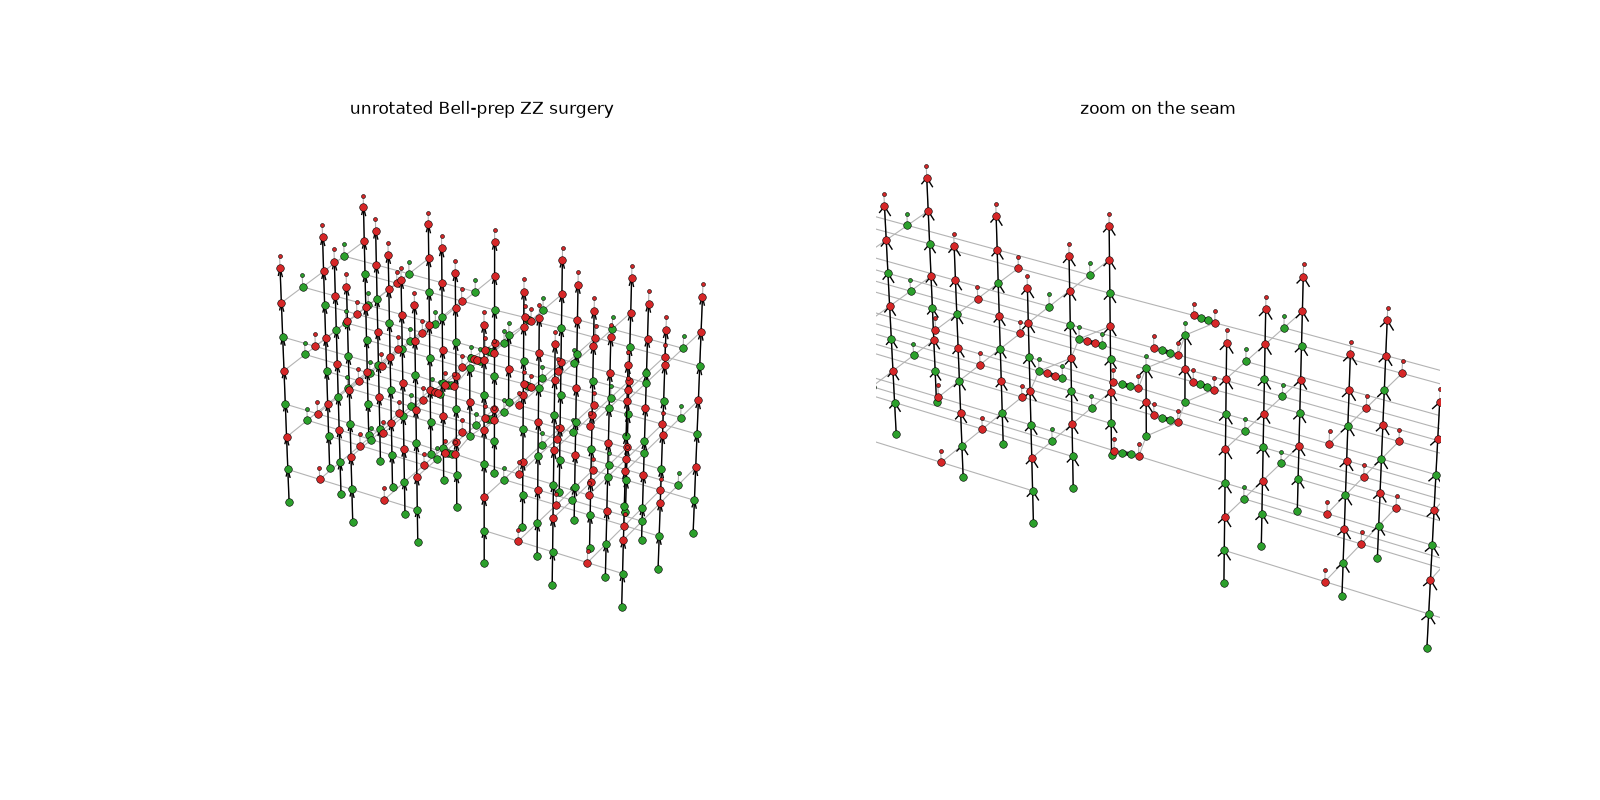

In [8]:
b = build("unrotated straight", 3, n_cycles=1)
fig = plt.figure(figsize=(16, 8))
b.experiment.draw(ax=fig.add_subplot(1, 2, 1, projection="3d"), title="unrotated Bell-prep ZZ surgery")
ax = b.experiment.draw(ax=fig.add_subplot(1, 2, 2, projection="3d"), title="zoom on the seam")
ax.set_xlim(3, 7)
plt.show()

## Graphlike distance

Both merge types, both observables, each noise model on its own and erasure
with circuit noise. The rotated straight seam drops to 2 in one sector; the
unrotated straight seam keeps d.

In [9]:
noises = NOISE | {"erasure+circuit": NOISE["erasure"] | NOISE["circuit"]}
for d in (3, 5):
    print(f"d={d}")
    print(f"  {'protocol':<20}{'merge':<7}{'obs':<5}" + "".join(f"{k:>17}" for k in noises))
    for name in PROTOCOLS:
        for merge in ("ZZ", "XX"):
            for obs in ("ZZ", "XX"):
                c = build(name, d, merge_type=merge, observable=obs).circuit
                print(f"  {name:<20}{merge:<7}{obs:<5}"
                      + "".join(f"{graphlike_distance(c, n) or '-':>17}" for n in noises.values()))

d=3
  protocol            merge  obs            erasure          circuit             prep  erasure+circuit
  rotated straight    ZZ     ZZ                   4                3                4                3
  rotated straight    ZZ     XX                   2                2                2                2
  rotated straight    XX     ZZ                   2                2                2                2
  rotated straight    XX     XX                   4                3                4                3
  rotated zigzag      ZZ     ZZ                   4                3                4                3
  rotated zigzag      ZZ     XX                   3                3                3                3
  rotated zigzag      XX     ZZ                   3                3                3                3
  rotated zigzag      XX     XX                   4                3                4                3
  unrotated straight  ZZ     ZZ                   4                3 

KeyboardInterrupt: 

## The DEM in 3D

Unrotated, d = 3, ZZ merge, XX observable (the sector the rotated straight
seam loses). Erasure edges are red; black is stim's shortest graphlike
logical error under all the channels.

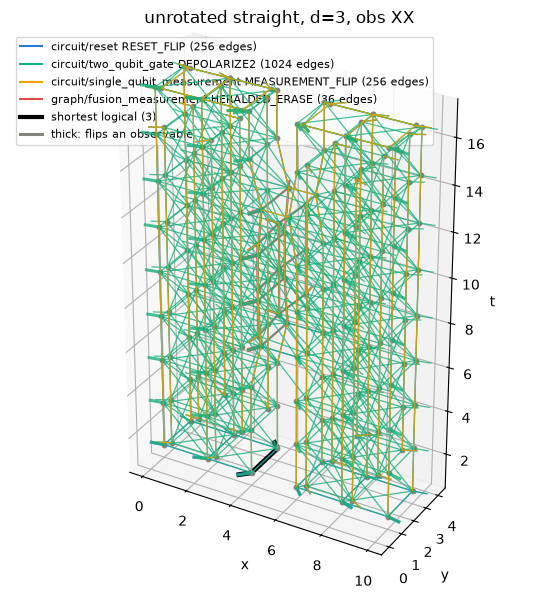

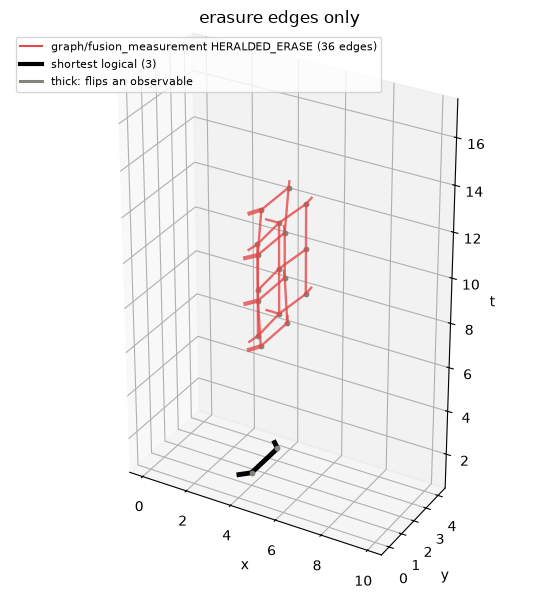

In [ ]:
noise = NOISE["erasure"] | NOISE["circuit"]
c = build("unrotated straight", 3, observable="XX").circuit
fig, ax, mechs = plot_dem(c, noise, title="unrotated straight, d=3, obs XX")
plt.show()
fig, ax, _ = plot_dem(c, noise, sources=["graph/fusion_measurement HERALDED_ERASE"],
                      title="erasure edges only")
plt.show()

## The interface as a planar sheet

`sheet=True` keeps only the detectors erasures can flip, flattened onto
(position along the seam, t); circles and squares are the two sides of the
seam. Only mechanisms lying entirely in the sheet are drawn, and the legend
says how much of the shortest logical error falls in it.

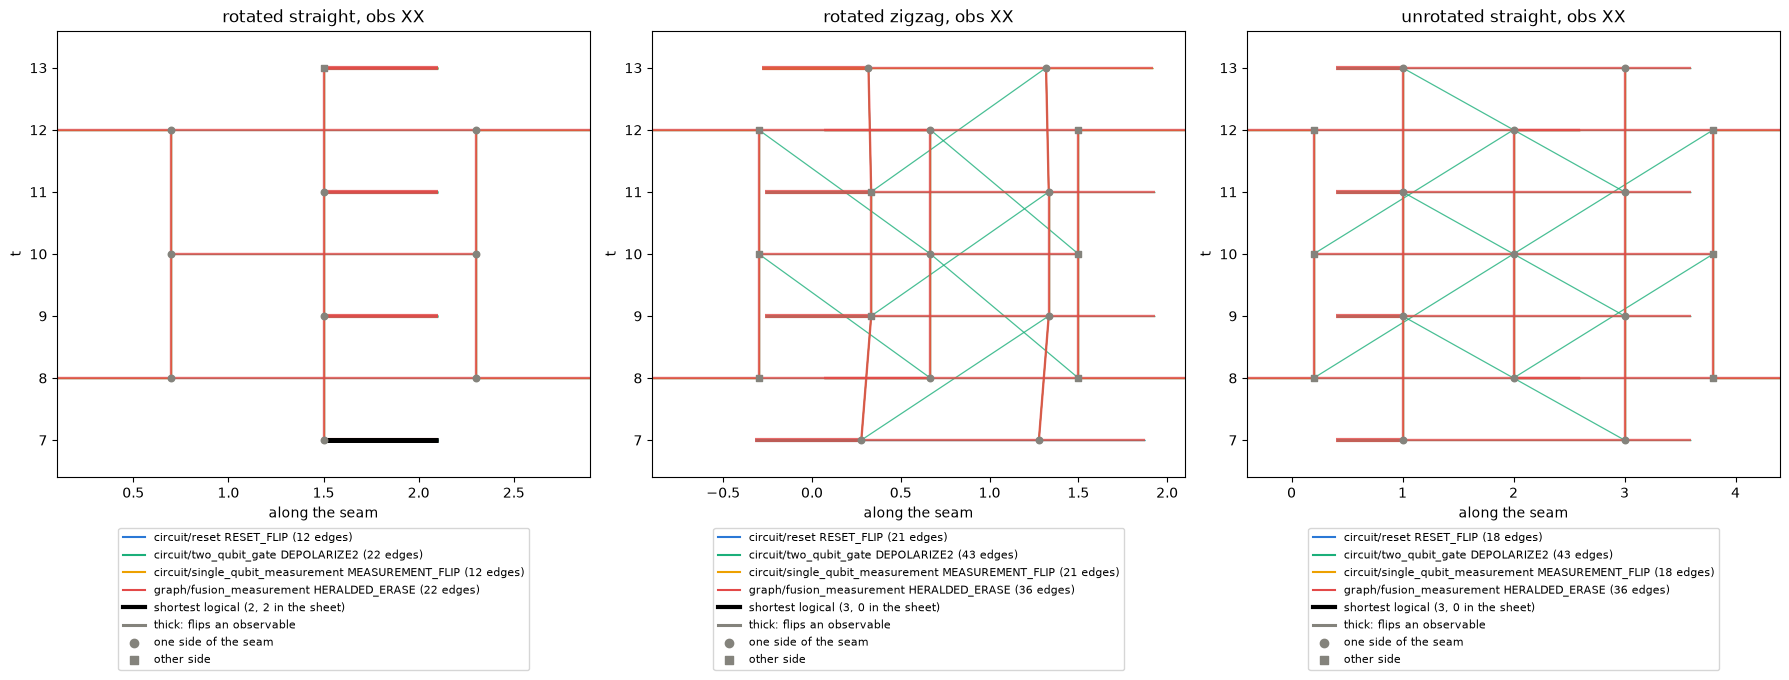

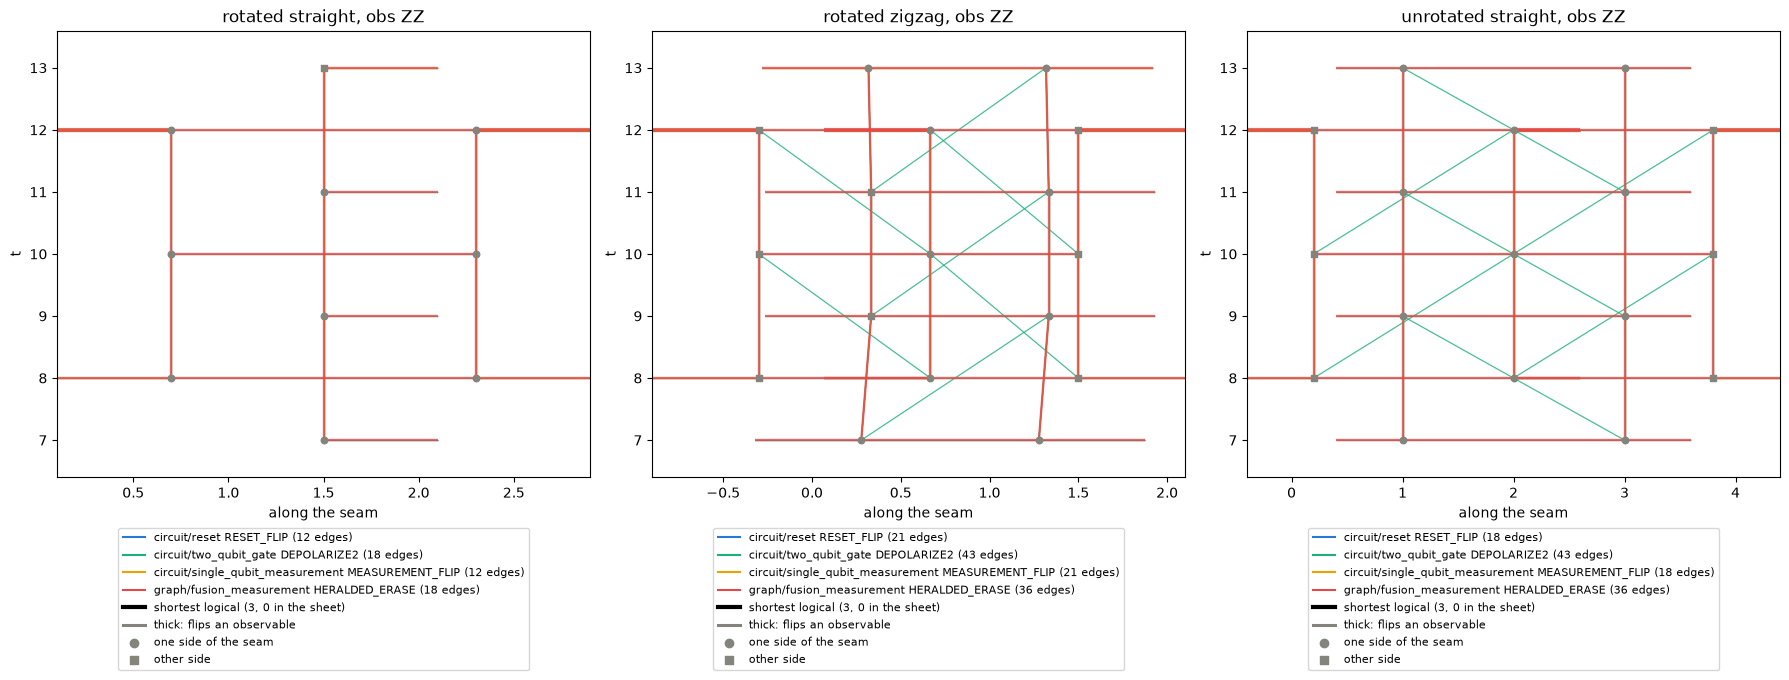

In [ ]:
d, noise = 3, NOISE["erasure"] | NOISE["circuit"]
for obs in ("XX", "ZZ"):
    fig, axes = plt.subplots(1, len(PROTOCOLS), figsize=(6 * len(PROTOCOLS), 7))
    for ax, name in zip(axes, PROTOCOLS):
        plot_dem(build(name, d, observable=obs).circuit, noise, ax=ax, sheet=True,
                 title=f"{name}, obs {obs}")
    fig.tight_layout()
    plt.show()

Erasure alone on the unrotated sheet, d = 5, for both observables:

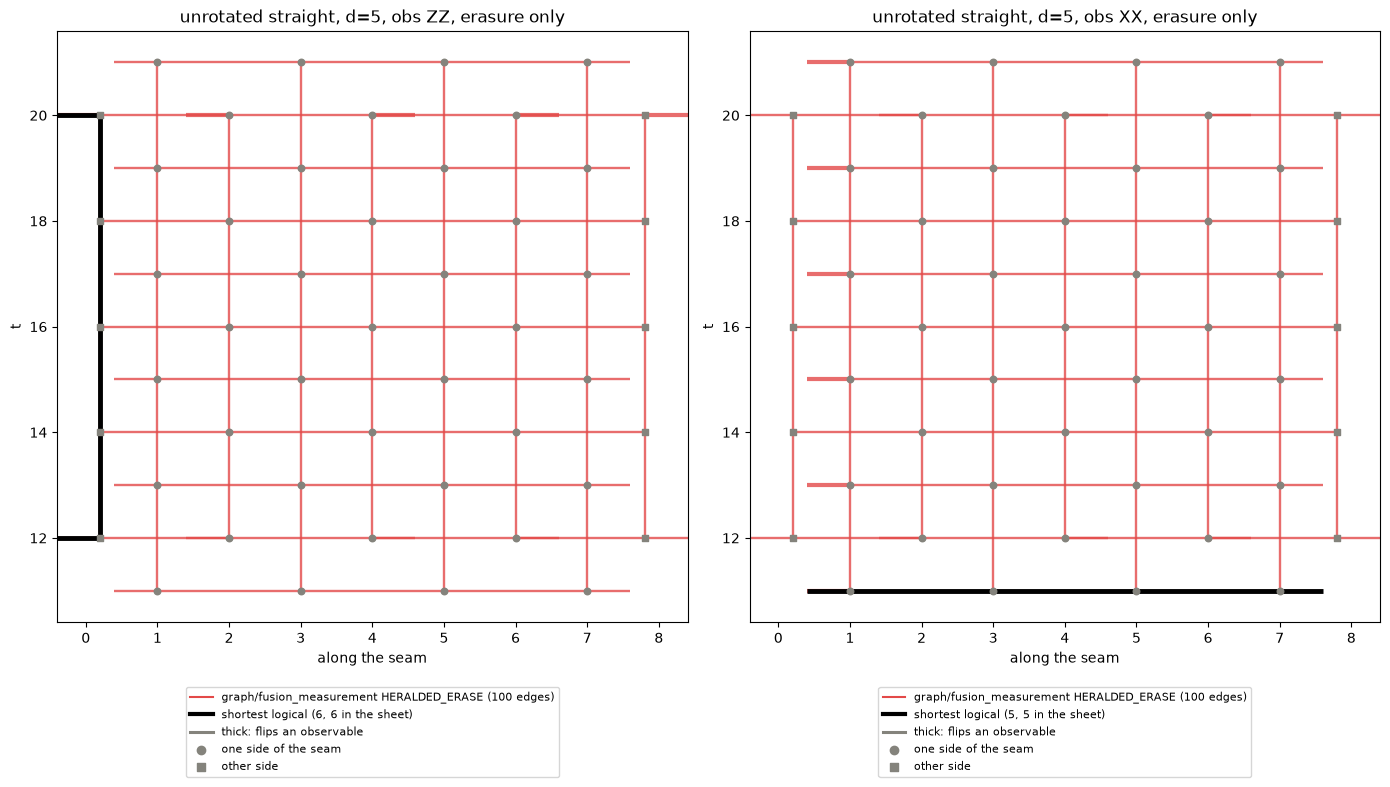

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, obs in zip(axes, ("ZZ", "XX")):
    plot_dem(build("unrotated straight", 5, observable=obs).circuit, NOISE["erasure"],
             ax=ax, sheet=True, title=f"unrotated straight, d=5, obs {obs}, erasure only")
fig.tight_layout()
plt.show()